In [12]:
!nvidia-smi

Fri Oct  9 15:53:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [10]:
!pip install -q fiftyone ultralytics "graphql-core>=3.2.6,<3.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.0/24.0 MB 76.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.2/268.2 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.5/112.5 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 103.3 MB/s

In [14]:
import PIL
print("Pillow:", PIL.__version__)

import fiftyone as fo
import fiftyone.zoo as foz
print("FiftyOne:", fo.__version__)

import ultralytics
print("Ultralytics:", ultralytics.__version__)

Pillow: 12.3.0
FiftyOne: 1.22.1
Ultralytics: 8.4.174


In [15]:
import fiftyone as fo
import fiftyone.zoo as foz

# keep the big download out of /kaggle/working (which has a 20 GB limit)
fo.config.dataset_zoo_dir = "/tmp/fiftyone"

dataset = foz.load_zoo_dataset(
    "open-images-v7",
    split="train",
    label_types=["detections"],
    classes=["Chair"],
    max_samples=2500,
    shuffle=True,
    seed=42,
    dataset_name="chair_oiv7",
    drop_existing_dataset=True,
)

print(dataset)
print("Label fields:", list(dataset.get_field_schema().keys()))

 100% |██████|    4.8Gb/4.8Gb [3.5s elapsed, 0s remaining, 1.5Gb/s]         
 100% |█████████████████| 2500/2500 [1.6m elapsed, 0s remaining, 26.0 files/s]      
Dataset info written to '/tmp/fiftyone/open-images-v7/info.json'
Loading 'open-images-v7' split 'train'
 100% |███████████████| 2500/2500 [47.4s elapsed, 0s remaining, 53.0 samples/s]      
Dataset 'chair_oiv7' created
Name:        chair_oiv7
Media type:  image
Num samples: 2500
Persistent:  False
Tags:        []
Sample fields:
    id:               fiftyone.core.fields.ObjectIdField
    filepath:         fiftyone.core.fields.StringField
    tags:             fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.ImageMetadata)
    created_at:       fiftyone.core.fields.DateTimeField
    last_modified_at: fiftyone.core.fields.DateTimeField
    ground_truth:     fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.labels.Detect

In [16]:
from fiftyone import ViewField as F

LABEL_FIELD = "ground_truth"
dets = F(f"{LABEL_FIELD}.detections")

# 1. keep only "Chair" labels
view = dataset.filter_labels(LABEL_FIELD, F("label") == "Chair", only_matches=True)

# 2. drop images that contain a group box or a drawing/cartoon of a chair
bad_box = (F("IsGroupOf") == True) | (F("IsDepiction") == True)
view = view.match(F(f"{LABEL_FIELD}.detections").filter(bad_box).length() == 0)

# 3. keep images that have at least one reasonably large chair (>2% of the image)
big_box = (F("bounding_box")[2] * F("bounding_box")[3]) > 0.02
view = view.match(F(f"{LABEL_FIELD}.detections").filter(big_box).length() > 0)

print("After label cleaning:", len(view))

After label cleaning: 2061


In [17]:
from PIL import Image

bad_ids = []
for s in view.select_fields():
    try:
        with Image.open(s.filepath) as im:
            im.verify()
    except Exception:
        bad_ids.append(s.id)

if bad_ids:
    view = view.exclude(bad_ids)

view = view.limit(2000)
print("Corrupt removed:", len(bad_ids))
print("Final images:", len(view))

Corrupt removed: 0
Final images: 2000


In [18]:
import fiftyone.utils.random as four

# clear old tags so re-running is safe
view.untag_samples(["train", "val", "test"])

four.random_split(view, {"train": 0.70, "val": 0.15, "test": 0.15}, seed=42)

for sp in ["train", "val", "test"]:
    print(sp, len(view.match_tags(sp)))

train 1400
val 300
test 300


In [19]:
import os, shutil

EXPORT_DIR = "/kaggle/working/chair_yolo"
if os.path.exists(EXPORT_DIR):
    shutil.rmtree(EXPORT_DIR)

for sp in ["train", "val", "test"]:
    view.match_tags(sp).export(
        export_dir=EXPORT_DIR,
        dataset_type=fo.types.YOLOv5Dataset,
        label_field=LABEL_FIELD,
        classes=["Chair"],
        split=sp,
    )

print("Exported to:", EXPORT_DIR)

 100% |███████████████| 1400/1400 [5.2s elapsed, 0s remaining, 294.3 samples/s]      
Directory '/kaggle/working/chair_yolo' already exists; export will be merged with existing files
 100% |█████████████████| 300/300 [1.2s elapsed, 0s remaining, 282.0 samples/s]         
Directory '/kaggle/working/chair_yolo' already exists; export will be merged with existing files
 100% |█████████████████| 300/300 [1.1s elapsed, 0s remaining, 275.9 samples/s]         
Exported to: /kaggle/working/chair_yolo


In [20]:
yaml_text = f"""path: {EXPORT_DIR}
train: images/train
val: images/val
test: images/test
names:
  0: chair
"""
with open(f"{EXPORT_DIR}/data.yaml", "w") as f:
    f.write(yaml_text)
print(yaml_text)

path: /kaggle/working/chair_yolo
train: images/train
val: images/val
test: images/test
names:
  0: chair



train images: 1400 | labels: 1400
val   images: 300 | labels: 300
test  images: 300 | labels: 300


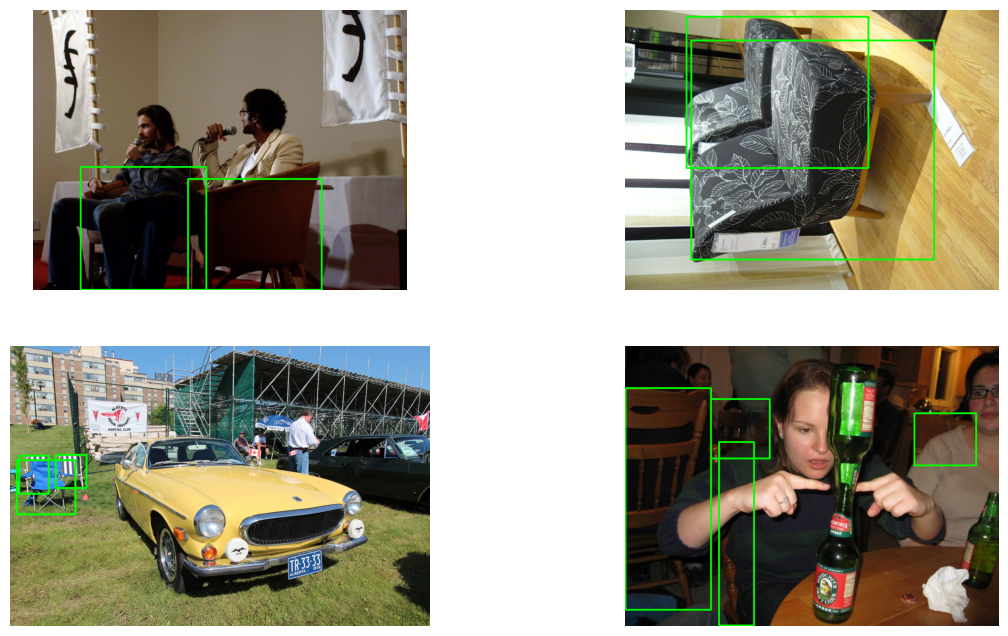

In [21]:
import glob, random
import cv2
import matplotlib.pyplot as plt

for sp in ["train", "val", "test"]:
    n_img = len(glob.glob(f"{EXPORT_DIR}/images/{sp}/*"))
    n_lbl = len(glob.glob(f"{EXPORT_DIR}/labels/{sp}/*.txt"))
    print(f"{sp:5s} images: {n_img} | labels: {n_lbl}")

imgs = random.sample(glob.glob(f"{EXPORT_DIR}/images/train/*.jpg"), 4)
plt.figure(figsize=(14, 8))
for i, p in enumerate(imgs):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl = p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    for line in open(lbl):
        _, cx, cy, bw, bh = map(float, line.split())
        x1, y1 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
        x2, y2 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 4)
    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.axis("off")
plt.show()

In [22]:
shutil.make_archive("/kaggle/working/chair_yolo_backup", "zip", "/kaggle/working", "chair_yolo")
print("Zip size (MB):", round(os.path.getsize("/kaggle/working/chair_yolo_backup.zip") / 1e6))

Zip size (MB): 610


In [23]:
import fiftyone as fo
import fiftyone.zoo as foz

fo.config.dataset_zoo_dir = "/tmp/fiftyone"

bg = foz.load_zoo_dataset(
    "open-images-v7",
    split="train",
    label_types=["detections"],
    classes=["Building", "Tree", "Car", "Table", "Couch", "Bed"],
    max_samples=900,
    shuffle=True,
    seed=7,
    dataset_name="bg_oiv7",
    drop_existing_dataset=True,
)
print("Candidates:", len(bg))

Necessary images already downloaded
Existing download of split 'train' is sufficient
Loading 'open-images-v7' split 'train'
 100% |█████████████████| 900/900 [17.7s elapsed, 0s remaining, 48.4 samples/s]      
Dataset 'bg_oiv7' created
Candidates: 900


In [24]:
import os, shutil, random, glob
from ultralytics import YOLO

EXPORT_DIR = "/kaggle/working/chair_yolo"

# pretrained COCO model already knows "chair" (class 56)
coco = YOLO("yolo11s.pt")
paths = [s.filepath for s in bg]

clean = []
for i in range(0, len(paths), 32):
    batch = paths[i:i + 32]
    results = coco.predict(batch, conf=0.20, classes=[56], verbose=False)
    for p, r in zip(batch, results):
        if len(r.boxes) == 0:
            clean.append(p)

print("No-chair images found:", len(clean))

random.seed(42)
random.shuffle(clean)
clean = clean[:500]

n = len(clean)
splits = {
    "train": clean[: int(0.70 * n)],
    "val":   clean[int(0.70 * n): int(0.85 * n)],
    "test":  clean[int(0.85 * n):],
}

for sp, files in splits.items():
    for p in files:
        name = "bg_" + os.path.basename(p)
        stem = os.path.splitext(name)[0]
        shutil.copy(p, f"{EXPORT_DIR}/images/{sp}/{name}")
        open(f"{EXPORT_DIR}/labels/{sp}/{stem}.txt", "w").close()   # empty label = "no chair here"
    print(sp, "background added:", len(files))

# delete old caches so YOLO re-reads the labels
for f in glob.glob(f"{EXPORT_DIR}/labels/*.cache"):
    os.remove(f)

No-chair images found: 38
train background added: 26
val background added: 6
test background added: 6


In [25]:
for sp in ["train", "val", "test"]:
    n_img = len(glob.glob(f"{EXPORT_DIR}/images/{sp}/*"))
    n_lbl = len(glob.glob(f"{EXPORT_DIR}/labels/{sp}/*.txt"))
    n_empty = sum(1 for f in glob.glob(f"{EXPORT_DIR}/labels/{sp}/*.txt") if os.path.getsize(f) == 0)
    print(f"{sp:5s} images: {n_img} | labels: {n_lbl} | background (empty): {n_empty}")
    

train images: 1426 | labels: 1426 | background (empty): 26
val   images: 306 | labels: 306 | background (empty): 6
test  images: 306 | labels: 306 | background (empty): 6


In [28]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

results = model.train(
    data=f"{EXPORT_DIR}/data.yaml",
    epochs=60,
    imgsz=640,
    batch=16,
    patience=12,
    device=0,
    workers=2,
    project="/kaggle/working/runs",
    name="chair_detector",
    exist_ok=True,
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/chair_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=chair_detector, nbs=64, nms=None, opset=None, optimiz

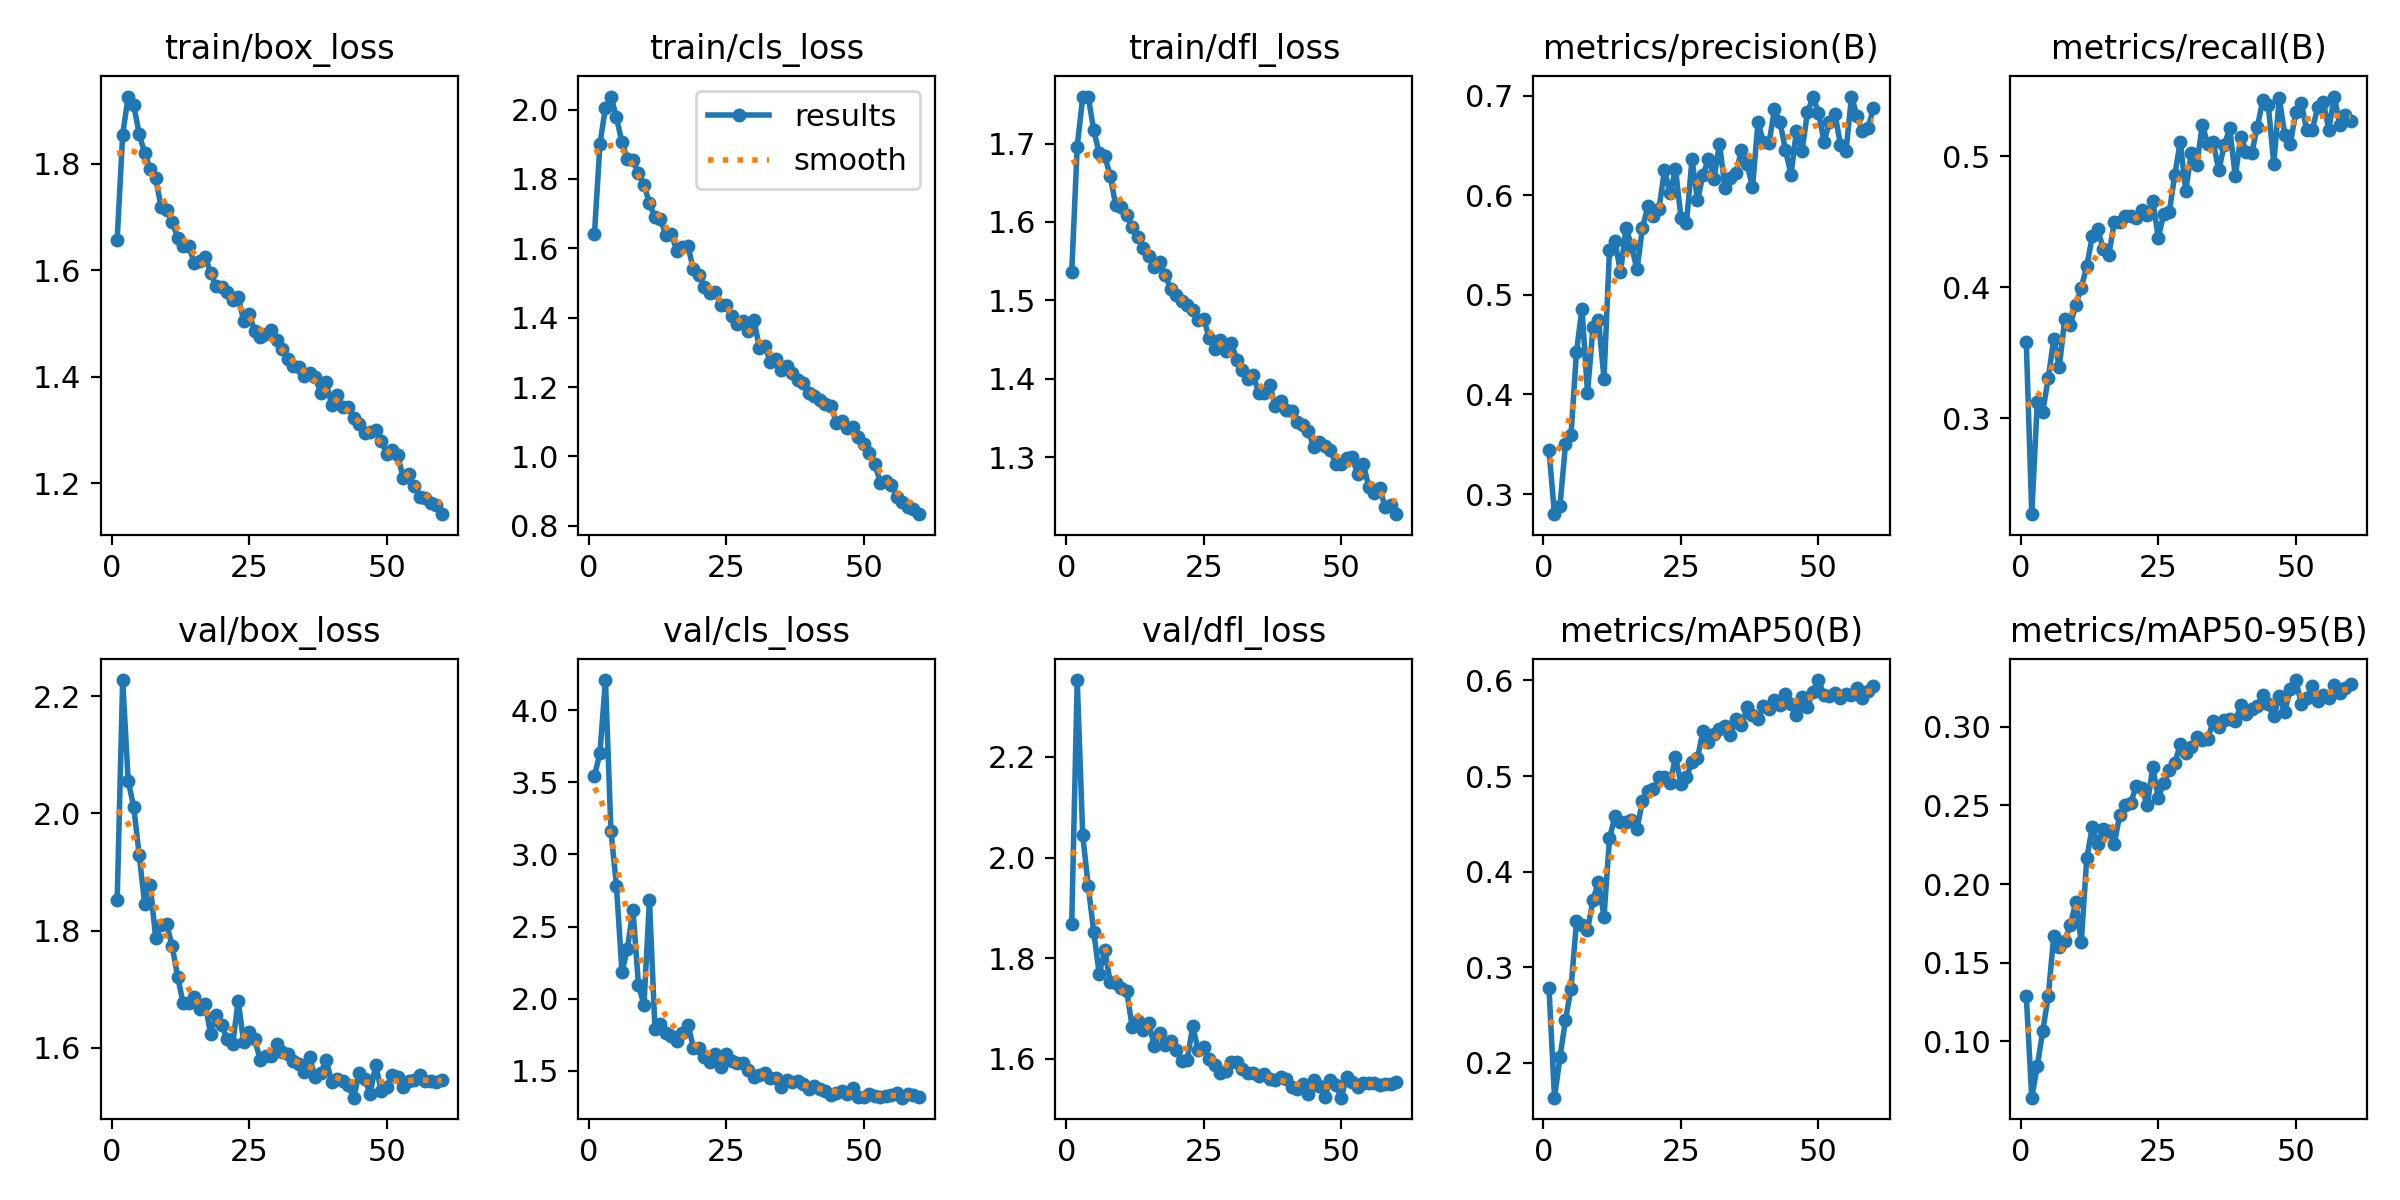

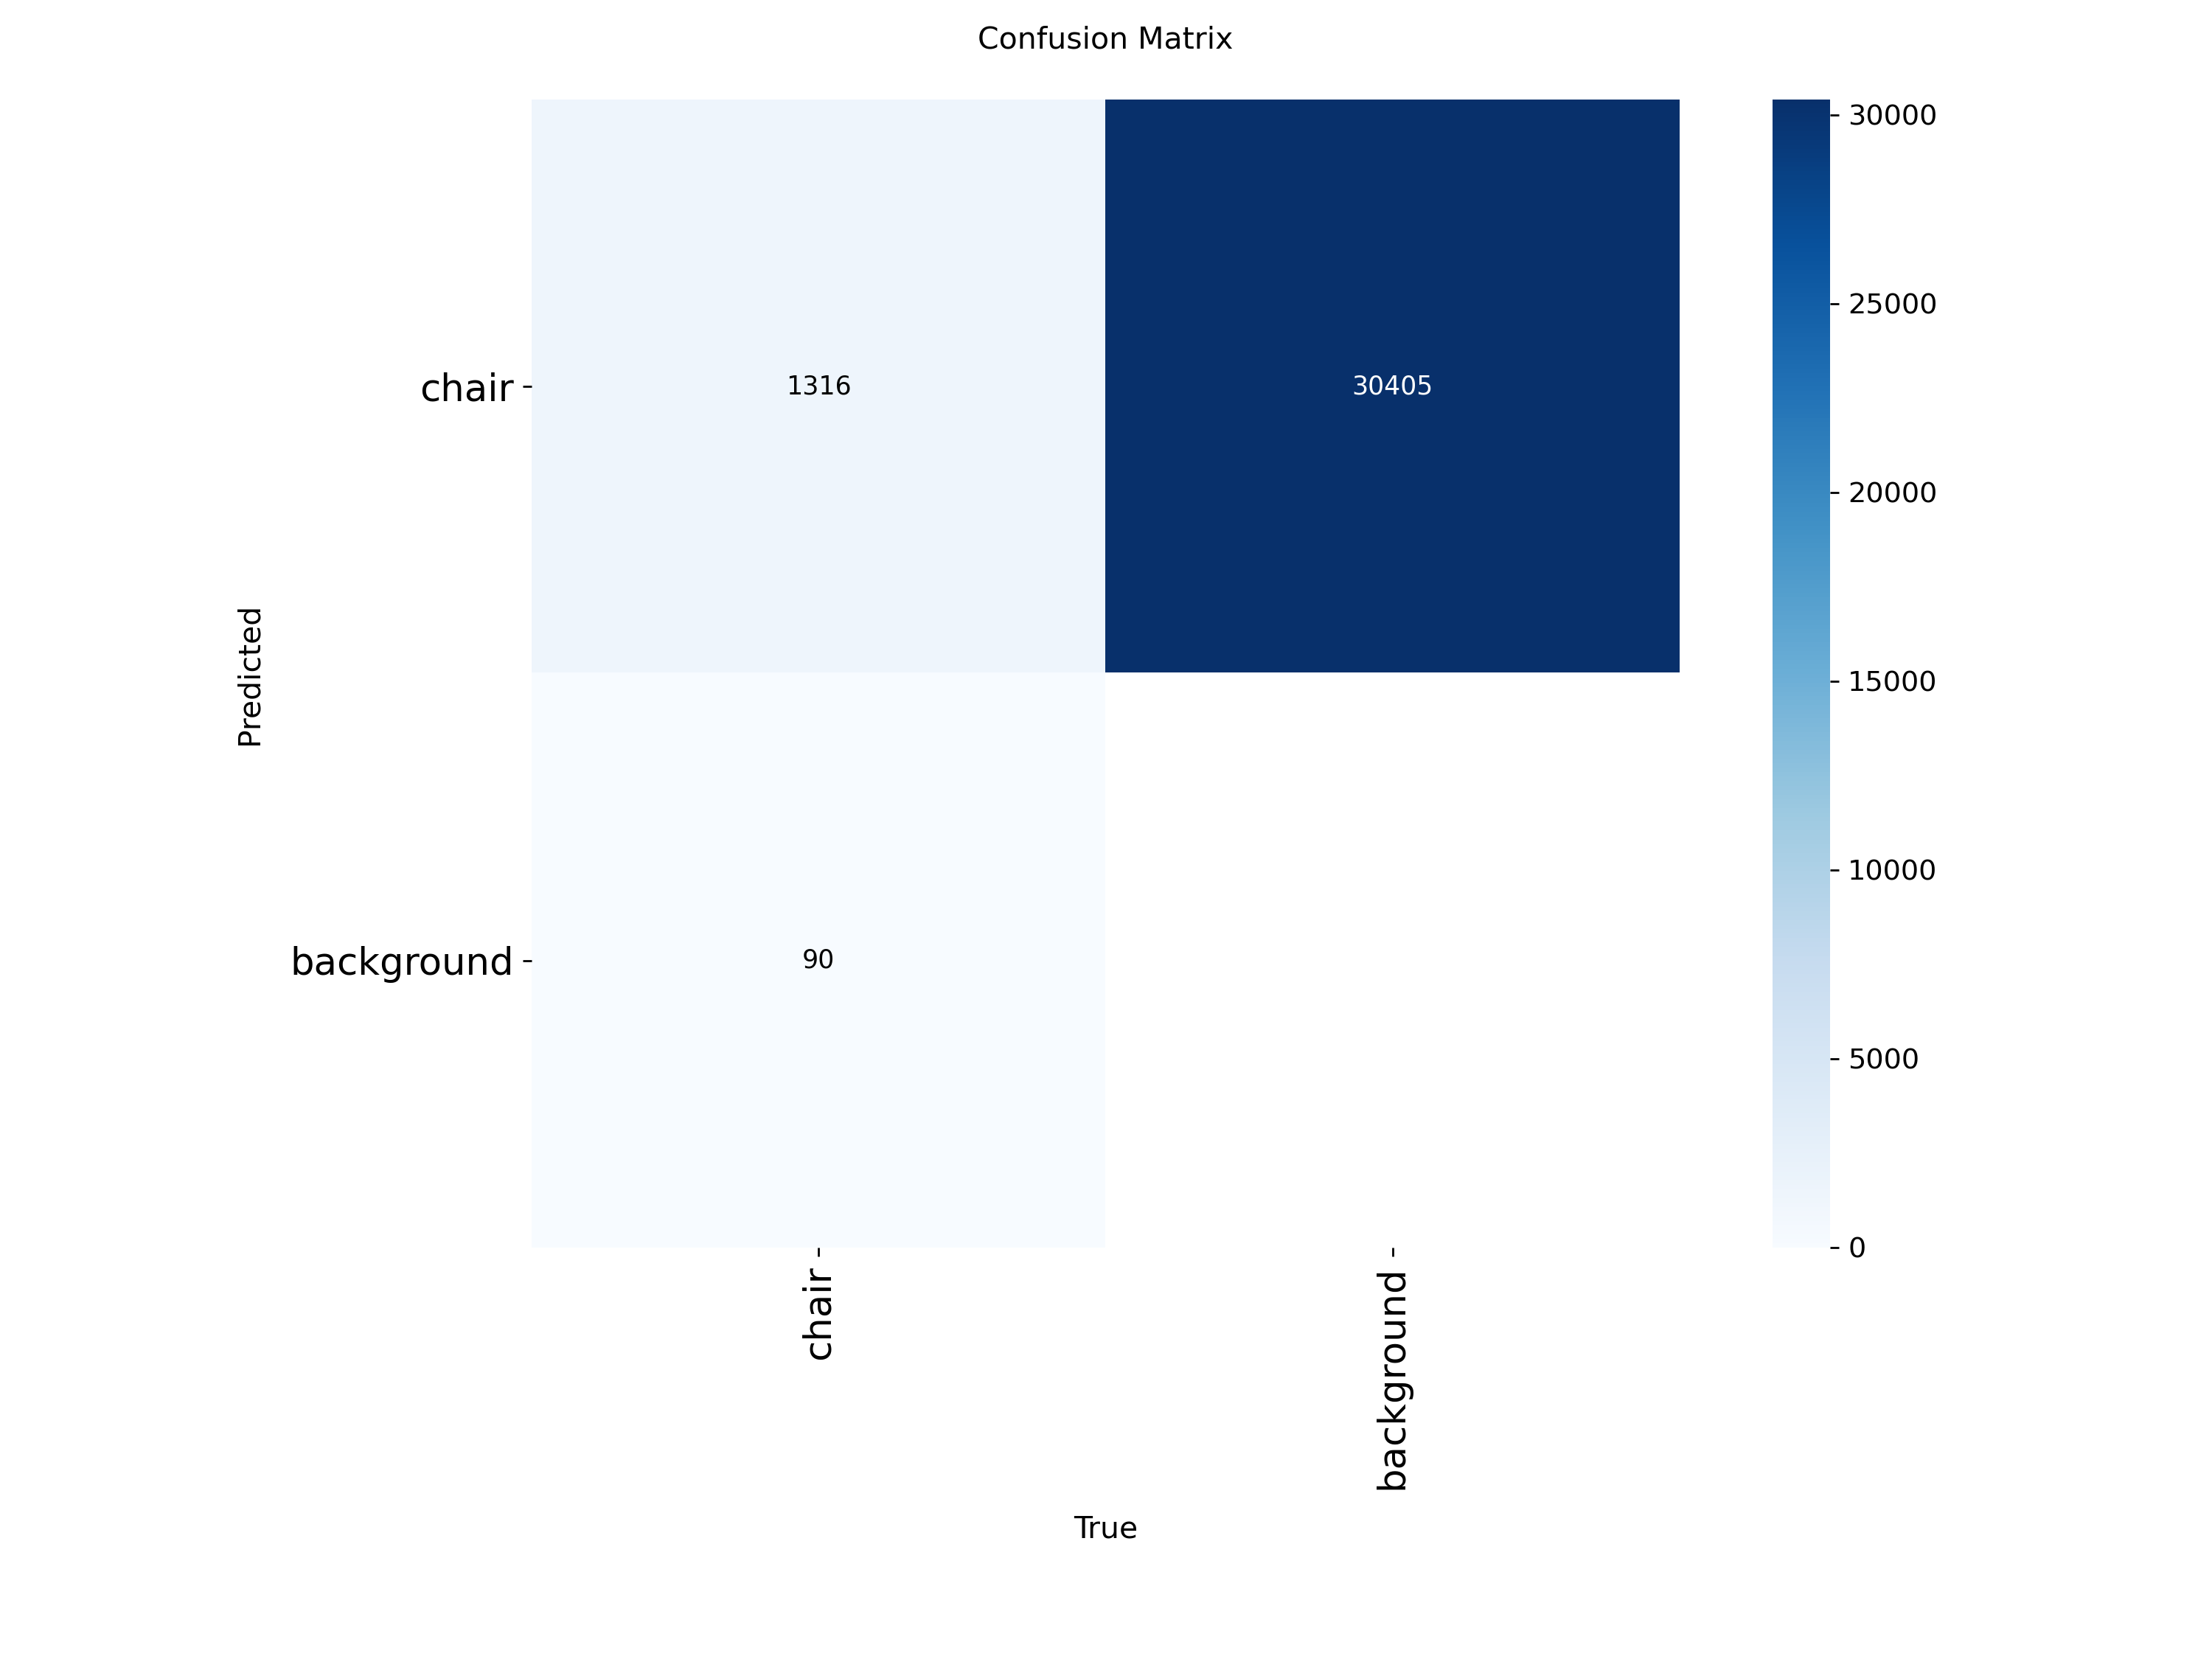

In [29]:
from IPython.display import Image, display

display(Image("/kaggle/working/runs/chair_detector/results.png"))
display(Image("/kaggle/working/runs/chair_detector/confusion_matrix.png"))

In [30]:
best = YOLO("/kaggle/working/runs/chair_detector/weights/best.pt")

m = best.val(data=f"{EXPORT_DIR}/data.yaml", split="test")
print("Test mAP50:   ", round(m.box.map50, 3))
print("Test mAP50-95:", round(m.box.map, 3))
print("Precision:    ", round(m.box.mp, 3), "| Recall:", round(m.box.mr, 3))

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1858.4±470.9 MB/s, size: 172.4 KB)
val: Scanning /kaggle/working/chair_yolo/labels/test... 306 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 306/306 902.3it/s 0.3s0.1s
val: New cache created: /kaggle/working/chair_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 3.5it/s 5.7s0.2s
                   all        306       1480      0.699      0.543      0.598      0.326
Speed: 1.4ms preprocess, 8.6ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
Test mAP50:    0.598
Test mAP50-95: 0.326
Precision:     0.699 | Recall: 0.543


In [31]:
import io, cv2, numpy as np
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from PIL import Image
from ultralytics import YOLO

best = YOLO("/kaggle/working/runs/chair_detector/weights/best.pt")
CONF = 0.5   # lower to 0.3 if real chairs are missed

uploader = widgets.FileUpload(accept="image/*", multiple=True)
button = widgets.Button(description="Run test", button_style="success")
out = widgets.Output()

def get_files(value):
    # works for both old (dict) and new (tuple) ipywidgets versions
    if isinstance(value, dict):
        return [(name, f["content"]) for name, f in value.items()]
    return [(f["name"], f["content"]) for f in value]

def run(_):
    with out:
        clear_output()
        files = get_files(uploader.value)
        if not files:
            print("Upload an image first, then click Run test.")
            return
        for name, content in files:
            img = Image.open(io.BytesIO(bytes(content))).convert("RGB")
            r = best.predict(np.array(img), conf=CONF, verbose=False)[0]
            n = len(r.boxes)
            if n:
                print(f"{name} -> CHAIR ({n} found, best {float(r.boxes.conf.max()):.0%})")
            else:
                print(f"{name} -> NOT A CHAIR")
            plt.figure(figsize=(6, 5))
            plt.imshow(r.plot()[:, :, ::-1])
            plt.axis("off")
            plt.show()

button.on_click(run)
display(uploader, button, out)

FileUpload(value=(), accept='image/*', description='Upload', multiple=True)

Button(button_style='success', description='Run test', style=ButtonStyle())

Output()

In [2]:
!pip install -q remotezip tqdm

In [2]:
!pip install -q icrawler imagehash

In [6]:
import os, glob, time, logging
from icrawler.builtin import BingImageCrawler, BaiduImageCrawler

RAW = "/kaggle/working/real_raw"
extra_intact = ["old wooden chair", "used chair", "chair in a room", "worn chair",
                "school chair", "kitchen chair", "plastic chair outdoor", "folding chair"]

for q in extra_intact:
    folder = f"{RAW}/intact/{q.replace(' ', '_')}"
    os.makedirs(folder, exist_ok=True)
    BingImageCrawler(storage={"root_dir": folder}, log_level=logging.WARNING).crawl(keyword=q, max_num=50)
    if len(glob.glob(folder + "/*")) < 10:
        time.sleep(5)
        BaiduImageCrawler(storage={"root_dir": folder}, log_level=logging.WARNING).crawl(keyword=q, max_num=50)
    time.sleep(3)

print("TOTAL intact:", len(glob.glob(f"{RAW}/intact/*/*")))

TOTAL intact: 399


In [7]:
import shutil, imagehash
from PIL import Image

CLEAN = "/kaggle/working/real_clean"
shutil.rmtree(CLEAN, ignore_errors=True)

for cls in ["damaged", "intact"]:
    os.makedirs(f"{CLEAN}/{cls}", exist_ok=True)
    seen, kept = set(), 0
    for p in sorted(glob.glob(f"{RAW}/{cls}/*/*")):
        try:
            with Image.open(p) as im:
                im = im.convert("RGB")
                if min(im.size) < 200:
                    continue
                h = imagehash.phash(im)
                if any(h - s <= 4 for s in seen):      # near-duplicate check
                    continue
                seen.add(h)
                im.save(f"{CLEAN}/{cls}/{kept:04d}.jpg", quality=92)
                kept += 1
        except Exception:
            continue
    print(cls, "kept:", kept)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


damaged kept: 258
intact kept: 351


In [12]:
!find /kaggle/input -name "*.pt" | head

In [14]:
!find /kaggle/working /kaggle/input -name "*.pt" 2>/dev/null

In [16]:
!find /kaggle -name "*.pt" 2>/dev/null

In [17]:
import os, glob

print("working exists:", os.path.exists("/kaggle/working"))
print("\nTop-level items in /kaggle/working:")
for n in sorted(os.listdir("/kaggle/working")):
    print("  ", n)

print("\n.pt files:", glob.glob("/kaggle/**/*.pt", recursive=True))

print("\nreal_clean damaged:", len(glob.glob("/kaggle/working/real_clean/damaged/*.jpg")))
print("real_clean intact: ", len(glob.glob("/kaggle/working/real_clean/intact/*.jpg")))

working exists: True

Top-level items in /kaggle/working:
   .virtual_documents
   real_clean
   real_raw

.pt files: []

real_clean damaged: 258
real_clean intact:  351


In [18]:
import shutil, os
shutil.make_archive("/kaggle/working/real_clean_backup", "zip", "/kaggle/working/real_clean")
print("Backup MB:", round(os.path.getsize("/kaggle/working/real_clean_backup.zip") / 1e6))

Backup MB: 231


In [19]:
from ultralytics import YOLO
import os, glob, shutil, cv2

det = YOLO("yolo11s.pt")        # downloads automatically (Internet must be On)

CLEAN = "/kaggle/working/real_clean"
CROPS = "/kaggle/working/real_crops"
shutil.rmtree(CROPS, ignore_errors=True)

for cls in ["damaged", "intact"]:
    os.makedirs(f"{CROPS}/{cls}", exist_ok=True)
    ok = none = 0
    for p in sorted(glob.glob(f"{CLEAN}/{cls}/*.jpg")):
        r = det.predict(p, conf=0.25, classes=[56], verbose=False)[0]   # 56 = chair
        if len(r.boxes) == 0:
            none += 1
            continue
        b = r.boxes[int(r.boxes.conf.argmax())]       # most confident chair only
        x1, y1, x2, y2 = map(int, b.xyxy[0])
        crop = cv2.imread(p)[max(0, y1):y2, max(0, x1):x2]
        if min(crop.shape[:2]) < 100:
            continue
        cv2.imwrite(f"{CROPS}/{cls}/{os.path.basename(p)}", crop)
        ok += 1
    print(cls, "cropped:", ok, "| no chair found:", none)

damaged cropped: 179 | no chair found: 77
intact cropped: 189 | no chair found: 158


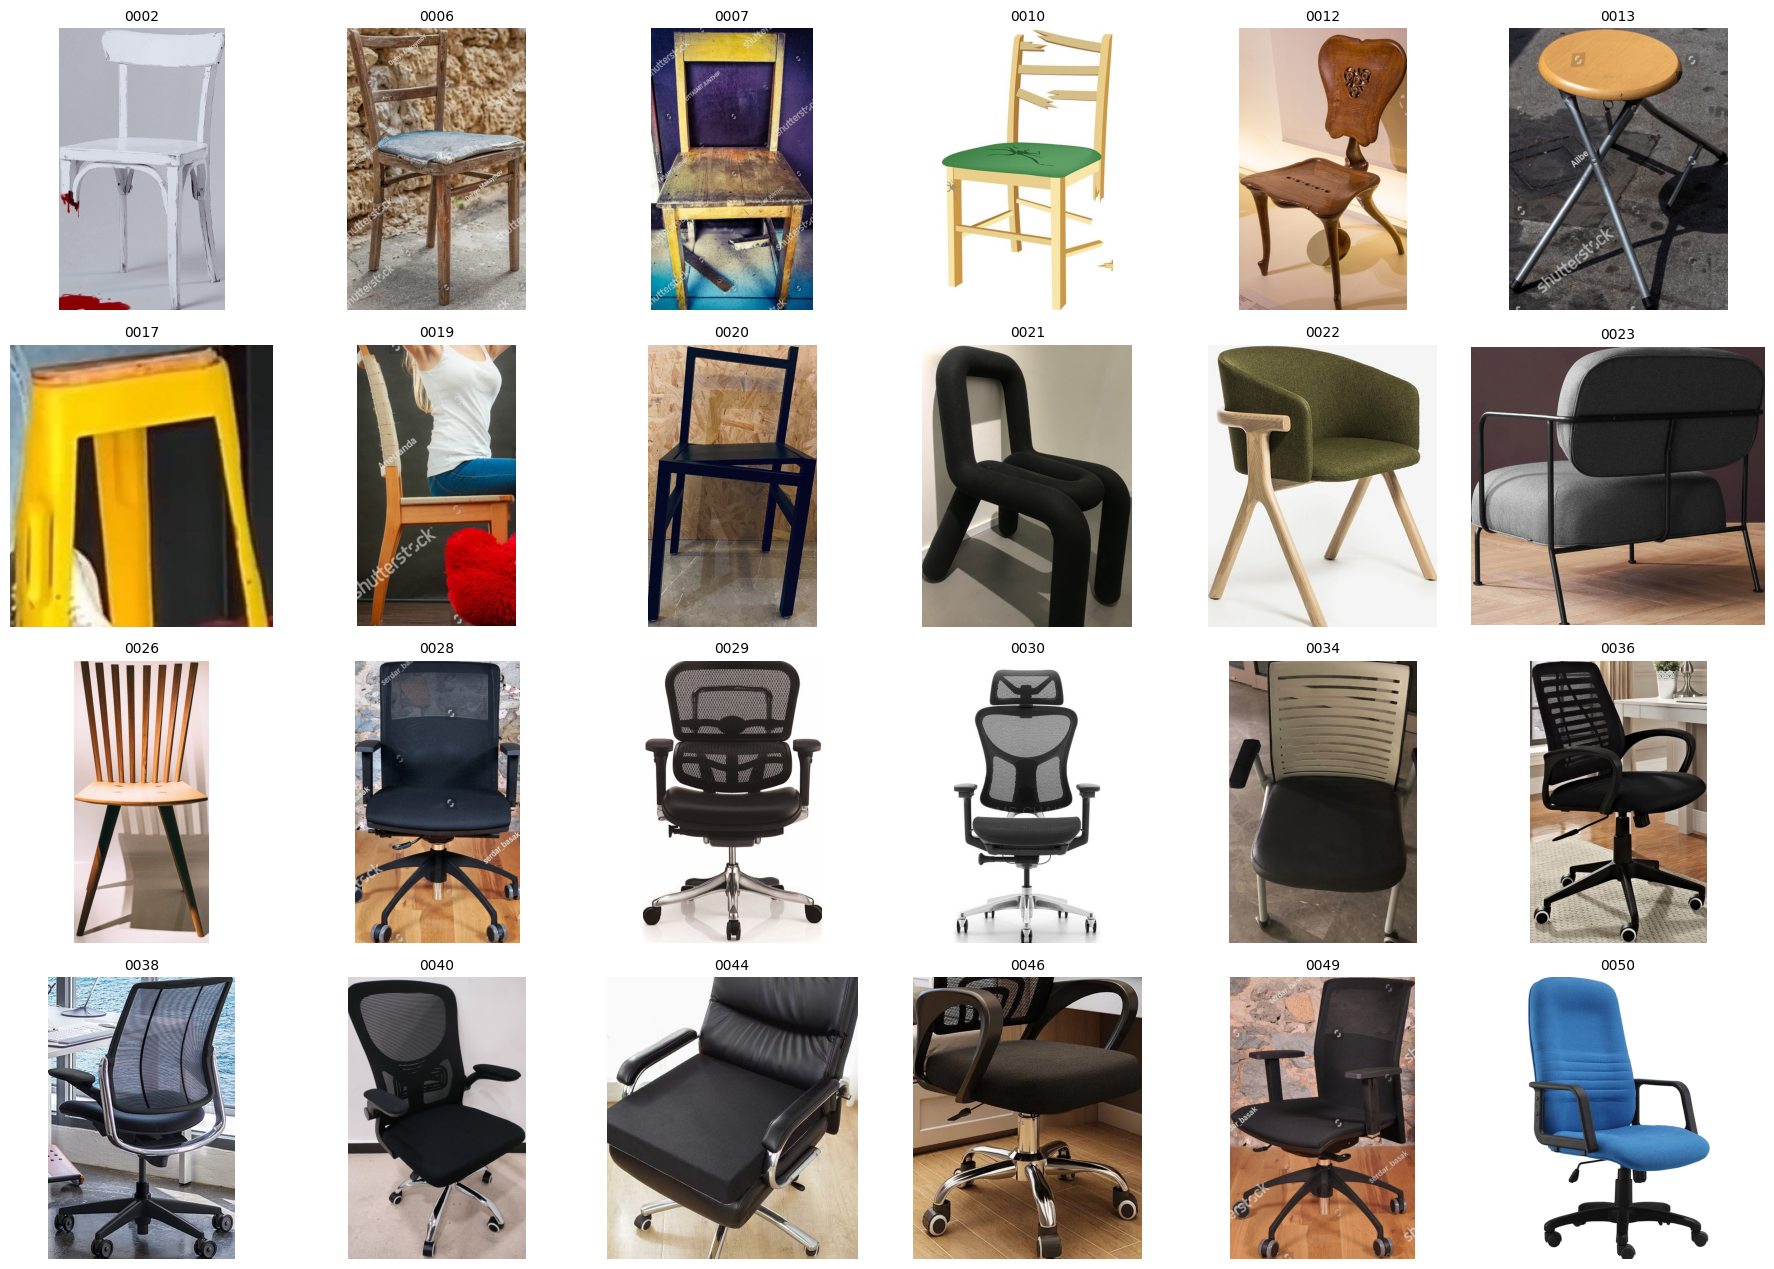

damaged: 179 images | page 1 of 8


In [20]:
import math
import matplotlib.pyplot as plt

def show_page(cls, page, per_page=24):
    files = sorted(glob.glob(f"{CROPS}/{cls}/*.jpg"))
    chunk = files[page * per_page:(page + 1) * per_page]
    rows = math.ceil(len(chunk) / 6)
    plt.figure(figsize=(18, 3.2 * rows))
    for i, f in enumerate(chunk):
        plt.subplot(rows, 6, i + 1)
        plt.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB))
        plt.title(os.path.basename(f)[:-4], fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    plt.show()
    print(f"{cls}: {len(files)} images | page {page + 1} of {math.ceil(len(files) / per_page)}")

show_page("damaged", 0)       # then 1, 2, 3 ... until you reach the last page

In [21]:
to_delete = {"damaged": ["0003", "0017"],     # put your own list here
             "intact":  []}
for cls, ids in to_delete.items():
    for i in ids:
        f = f"{CROPS}/{cls}/{i}.jpg"
        if os.path.exists(f):
            os.remove(f)
for cls in ["damaged", "intact"]:
    print(cls, "now:", len(glob.glob(f"{CROPS}/{cls}/*.jpg")))

damaged now: 178
intact now: 189


In [22]:
import shutil, os
shutil.make_archive("/kaggle/working/real_crops_backup", "zip", "/kaggle/working/real_crops")
print("Backup MB:", round(os.path.getsize("/kaggle/working/real_crops_backup.zip") / 1e6))

Backup MB: 75


In [23]:
import glob, random, shutil, os
random.seed(42)

CROPS = "/kaggle/working/real_crops"
FINAL = "/kaggle/working/damage_real"
shutil.rmtree(FINAL, ignore_errors=True)

name_map = {"damaged": "damaged", "intact": "not_damaged"}
files = {c: sorted(glob.glob(f"{CROPS}/{c}/*.jpg")) for c in name_map}
n_keep = min(len(v) for v in files.values())        # equal size for both classes
print("Using", n_keep, "images per class")

for c, fl in files.items():
    random.shuffle(fl)
    fl = fl[:n_keep]
    parts = {"train": fl[:int(0.70 * n_keep)],
             "val":   fl[int(0.70 * n_keep):int(0.85 * n_keep)],
             "test":  fl[int(0.85 * n_keep):]}
    for sp, lst in parts.items():
        os.makedirs(f"{FINAL}/{sp}/{name_map[c]}", exist_ok=True)
        for f in lst:
            shutil.copy(f, f"{FINAL}/{sp}/{name_map[c]}/{os.path.basename(f)}")
        print(f"{sp:5s} {name_map[c]:12s} {len(lst)}")

Using 178 images per class
train damaged      124
val   damaged      27
test  damaged      27
train not_damaged  124
val   not_damaged  27
test  not_damaged  27


In [24]:
from ultralytics import YOLO

clf = YOLO("yolo11s-cls.pt")
clf.train(
    data=FINAL,
    epochs=50,
    imgsz=224,
    batch=16,
    patience=15,
    device=0,                 # GPU T4 must be on
    project="/kaggle/working/runs",
    name="damage_real",
    exist_ok=True,
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/damage_real, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=damage_real, nbs=64, nms=None, opset=None, optimize=False,

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50     0.557G     0.4908          8        224: 100% ━━━━━━━━━━━━ 16/16 15.1it/s 1.1s0.2s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 2/2 40.4it/s 0.0s
                   all      0.611          1

      Epoch    GPU_mem       loss  Instances       Size
       3/50     0.557G     0.3595          8        224: 100% ━━━━━━━━━━━━ 16/16 10.3it/s 1.6s.2s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 2/2 72.7it/s 0.0s
                   all      0.611          1

      Epoch    GPU_mem       loss  Instances       Size
       4/50     0.557G     0.4519          8        224: 100% ━━━━━━━━━━━━ 16/16 11.4it/s 1.4s.2s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 2/2 60.7it/s 0.0s
                   all        0.5          1

      Epoch    GPU_mem       loss  Instances       Size
       5/50     0.557G     0.4772          8        224: 100% ━━━━━━━━━━━━ 16/16 9.9it/s 1.6s0.2s
               classes   top1_acc   top5_acc: 100% ━━━━

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bb9ba9d91d0>
curves: []
curves_results: []
fitness: 0.8333333432674408
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.6666666865348816, 'metrics/accuracy_top5': 1.0, 'fitness': 0.8333333432674408}
save_dir: PosixPath('/kaggle/working/runs/damage_real')
speed: {'preprocess': 0.41441824074623856, 'inference': 17.788457203702517, 'loss': 0.0003168888893183235, 'postprocess': 0.0004181111105733887}
top1: 0.6666666865348816
top5: 1.0

In [25]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

best_cls = YOLO("/kaggle/working/runs/damage_real/weights/best.pt")

true, pred = [], []
for cls in ["damaged", "not_damaged"]:
    for p in glob.glob(f"{FINAL}/test/{cls}/*.jpg"):
        r = best_cls.predict(p, verbose=False)[0]
        true.append(cls)
        pred.append(r.names[r.probs.top1])

print("Test accuracy:", round(float(np.mean(np.array(true) == np.array(pred))), 3))
print(confusion_matrix(true, pred, labels=["damaged", "not_damaged"]))
print(classification_report(true, pred, digits=3))

Test accuracy: 0.611
[[22  5]
 [16 11]]
              precision    recall  f1-score   support

     damaged      0.579     0.815     0.677        27
 not_damaged      0.688     0.407     0.512        27

    accuracy                          0.611        54
   macro avg      0.633     0.611     0.594        54
weighted avg      0.633     0.611     0.594        54



In [27]:
import io, os, cv2, numpy as np
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from PIL import Image
from ultralytics import YOLO

# ---- models ----
DAMAGE_MODEL = "/kaggle/working/runs/damage_real/weights/best.pt"   # or /kaggle/working/damage_classifier_best.pt
assert os.path.exists(DAMAGE_MODEL), "Damage model not found. Run: !find /kaggle -name '*.pt'"

chair_det = YOLO("yolo11s.pt")            # pretrained COCO model, class 56 = chair
damage_cls = YOLO(DAMAGE_MODEL)

CHAIR_CONF = 0.25      # lower it if real chairs are not detected

def analyze(img_rgb):
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    r = chair_det.predict(bgr, conf=CHAIR_CONF, classes=[56], verbose=False)[0]
    if len(r.boxes) == 0:
        return bgr, "NOT A CHAIR (no chair detected)", None

    out = bgr.copy()
    verdicts = []
    for b in r.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0])
        crop = bgr[max(0, y1):y2, max(0, x1):x2]
        if min(crop.shape[:2]) < 30:
            continue
        c = damage_cls.predict(crop, verbose=False)[0]
        label, conf = c.names[c.probs.top1], float(c.probs.top1conf)
        verdicts.append((label, conf))
        color = (0, 0, 255) if label == "damaged" else (0, 180, 0)
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 4)
        cv2.putText(out, f"{label} {conf:.0%}", (x1, max(25, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, color, 3)
    if not verdicts:
        return bgr, "Chair found but too small to judge", None
    overall = "DAMAGED" if any(v[0] == "damaged" for v in verdicts) else "NOT DAMAGED"
    return out, overall, verdicts

# ---- upload widget ----
uploader = widgets.FileUpload(accept="image/*", multiple=True)
button = widgets.Button(description="Run test", button_style="success")
out_area = widgets.Output()

def get_files(value):
    if isinstance(value, dict):                       # older ipywidgets
        return [(n, f["content"]) for n, f in value.items()]
    return [(f["name"], f["content"]) for f in value]  # newer ipywidgets

def run(_):
    with out_area:
        clear_output()
        files = get_files(uploader.value)
        if not files:
            print("Upload an image first, then click Run test.")
            return
        for name, content in files:
            img = np.array(Image.open(io.BytesIO(bytes(content))).convert("RGB"))
            annotated, verdict, details = analyze(img)
            print(f"{name} -> {verdict}")
            if details:
                for label, conf in details:
                    print(f"    chair: {label} ({conf:.0%})")
            plt.figure(figsize=(6, 5))
            plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
            plt.axis("off")
            plt.show()

button.on_click(run)
display(uploader, button, out_area)

FileUpload(value=(), accept='image/*', description='Upload', multiple=True)

Button(button_style='success', description='Run test', style=ButtonStyle())

Output()